# Comparison of some models with the data

In [1]:
import sys
sys.path.append("../")
from utils import *

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.metrics import r2_score, f1_score, mean_squared_error, make_scorer, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

## Importing data

In [2]:
#import the data and clean it a little
raw_data = pd.read_csv("../residential_solar_installations_panel_data_contiguous_US.csv", index_col=0)

features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)']

columns = features + ['cumulative num of residential PVs by 2016', 'number of buildings']

raw_data = raw_data.dropna(axis=0, how='any', subset=columns) #drop all the rows that have any missing values in the columns we care about
raw_data = raw_data[raw_data['number of buildings']>0] #only keep rows with at least some buildings in them

In [3]:
#group by county
blockgroups_fips = [fips if len(fips)==12 else '0'+fips for fips in raw_data.index.astype(str).values]
county_codes = [fips[:5] for fips in blockgroups_fips]

raw_data['County code'] = county_codes

columns += ['County code']

raw_data = raw_data[columns].groupby('County code').agg({
    'avg GHI (W/m^2)':'mean', 
    'ACS: number of households (2016)':'sum', 
    'ACS: housing unit density (/mile^2, 2016)':'mean',
    'ACS: median household income (inflation adjusted $ in 2016, 2016)':'median', 
    'ACS: % housing units occupied (2016)':'mean', 
    'ACS: % housing units occupied by renters (2016)':'mean',
    'ACS: avg number of years of education (2016)':'mean', 
    'ACS: median age': 'median', 
    'ACS: racial diversity (Gini Simpson index)':'mean',
    'cumulative num of residential PVs by 2016':'sum',
    'number of buildings':'sum'
})

#add state features
raw_data['state'] = [states_dict[i] for i in  raw_data.index.str[:2]]
state_one_hot = pd.get_dummies(raw_data['state'])
raw_data = pd.concat([raw_data, state_one_hot], axis=1)
features += state_one_hot.columns.tolist()

In [4]:
X = raw_data[features].to_numpy()
y = (raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']).to_numpy().reshape(-1,1)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=17)
# X_train, X_test, y_train, y_test = train_test_split(X[y.flatten()!=0], y[y.flatten()!=0], test_size=0.1, random_state=17)

## Linear regressions

In [134]:
alphas = np.logspace(-5, -3, 100)
scores = []

for alpha in alphas:
    model = Pipeline([('scale', StandardScaler()), ('model', Lasso(alpha=alpha))])
    scores.append(cross_val_score(model, X_train, y_train, cv=5, n_jobs=5))
    
scores = np.array(scores)

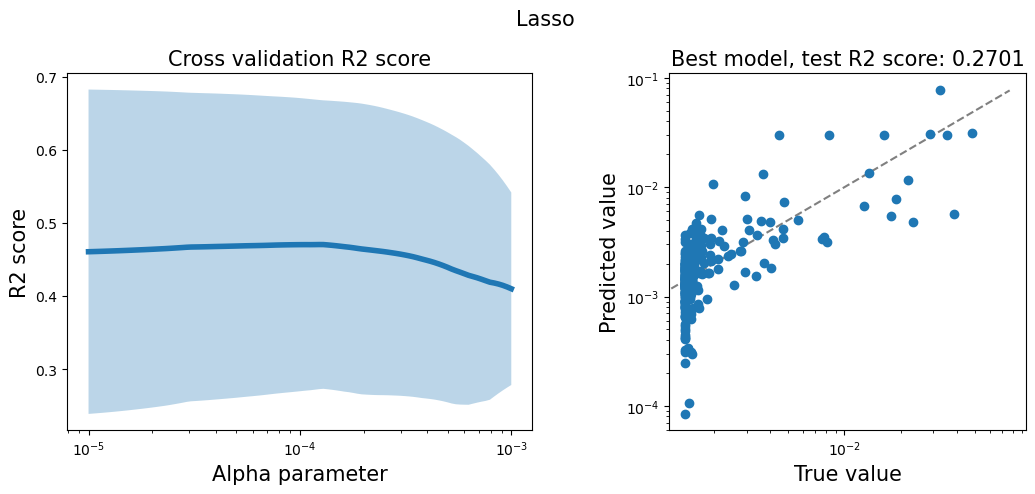

In [135]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax[0].plot(alphas, means, linewidth=4)
ax[0].fill_between(alphas, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_title("Cross validation R2 score", fontsize=15)
ax[0].set_xlabel("Alpha parameter", fontsize=15)
ax[0].set_ylabel("R2 score", fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].set_xscale('log')

model = Pipeline([('scale', StandardScaler()), ('model', Lasso(alpha=alphas[means.argmax()]))])
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax[1].scatter(y_test-minval, y_pred-minval, zorder=10)
ax[1].plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax[1].set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax[1].set_xlabel("True value", fontsize=15)
ax[1].set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax[1].set_ylim(minval, maxval)
ax[1].set_box_aspect(1)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

fig.suptitle("Lasso", fontsize=15)
fig.tight_layout()

In [82]:
alphas = np.logspace(1, 4, 100)
scores = []

for alpha in alphas:
    model = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=alpha))])
    scores.append(cross_val_score(model, X_train, y_train, cv=5, n_jobs=5))
    
scores = np.array(scores)

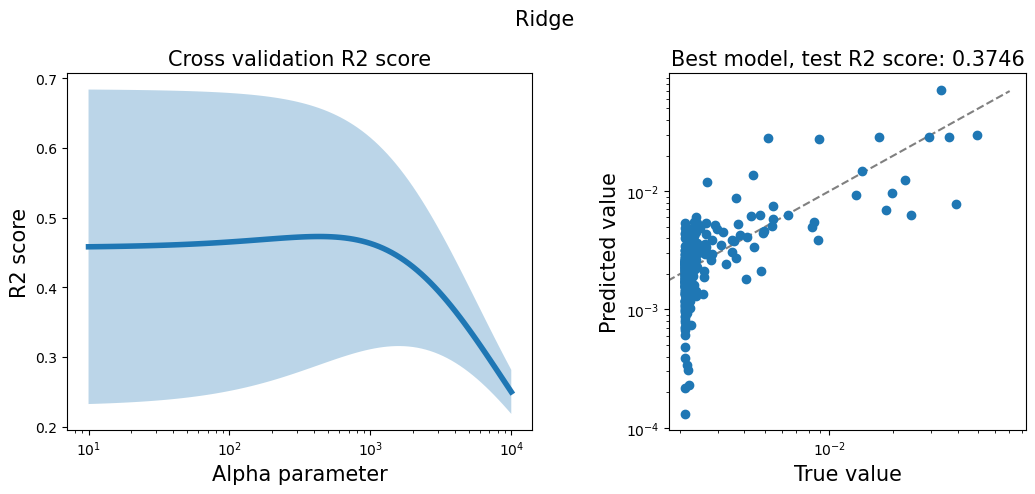

In [83]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax[0].plot(alphas, means, linewidth=4)
ax[0].fill_between(alphas, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_title("Cross validation R2 score", fontsize=15)
ax[0].set_xlabel("Alpha parameter", fontsize=15)
ax[0].set_ylabel("R2 score", fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].set_xscale('log')

model = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=alphas[means.argmax()]))])
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax[1].scatter(y_test-minval, y_pred-minval, zorder=10)
ax[1].plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax[1].set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax[1].set_xlabel("True value", fontsize=15)
ax[1].set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax[1].set_ylim(minval, maxval)
ax[1].set_box_aspect(1)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

fig.suptitle("Ridge", fontsize=15)
fig.tight_layout()

## Forest based methods

In [21]:
n_ests = np.linspace(10, 200, 25).astype(int)
scores = []
model_type = RandomForestRegressor

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = model_type(n_estimators=n_est, n_jobs=8)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 25/25, ETA: 16:21:59 (average time per iteration: 2.386s)


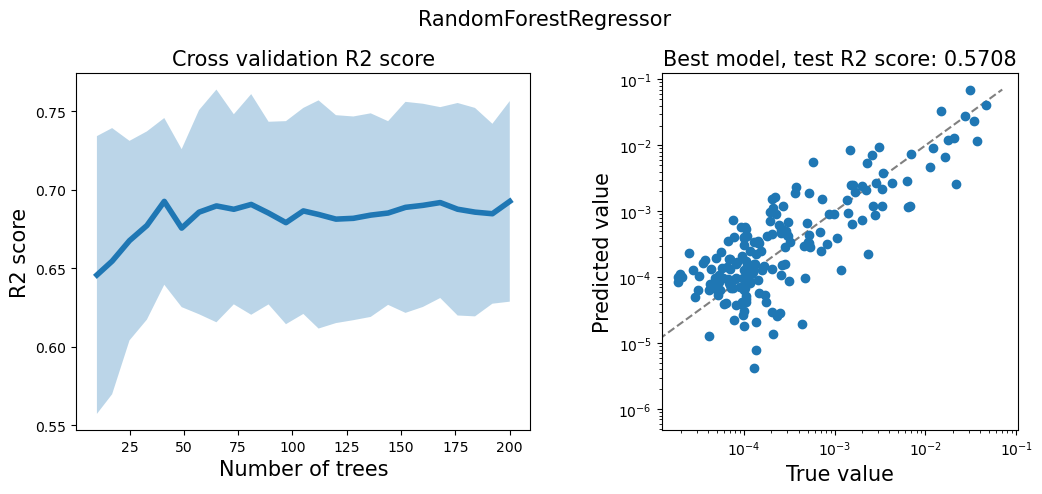

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax[0].plot(n_ests, means, linewidth=4)
ax[0].fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_title("Cross validation R2 score", fontsize=15)
ax[0].set_xlabel("Number of trees", fontsize=15)
ax[0].set_ylabel("R2 score", fontsize=15)
ax[0].tick_params(labelsize=10)

model = model_type(n_estimators=n_ests[means.argmax()], n_jobs=8)
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax[1].scatter(y_test-minval, y_pred-minval, zorder=10)
ax[1].plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax[1].set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax[1].set_xlabel("True value", fontsize=15)
ax[1].set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax[1].set_ylim(minval, maxval)
ax[1].set_box_aspect(1)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

fig.suptitle(model_type.__name__, fontsize=15)
fig.tight_layout()

In [23]:
n_ests = np.linspace(50, 300, 50).astype(int)
scores = []
model_type = GradientBoostingRegressor

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = model_type(n_estimators=n_est)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5, n_jobs=5))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 50/50, ETA: 16:23:06 (average time per iteration: 1.289s)


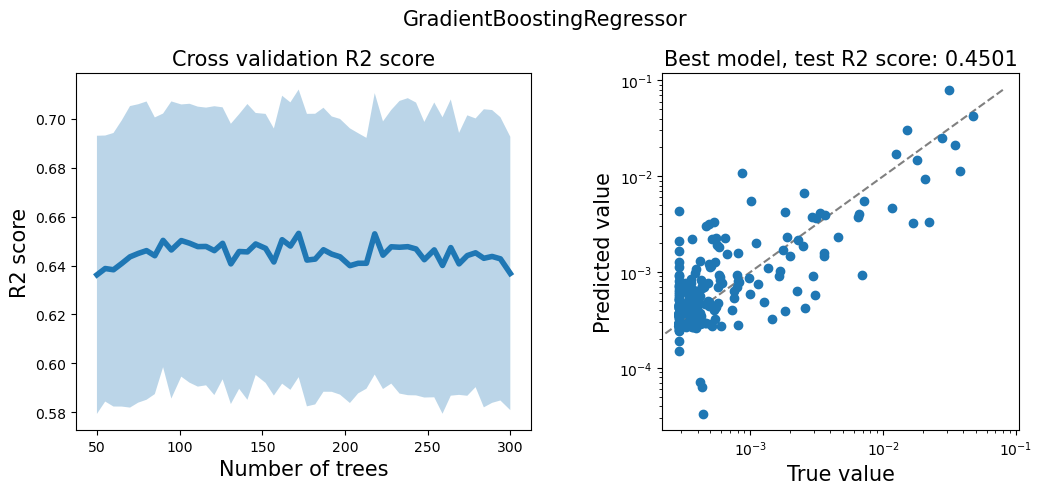

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax[0].plot(n_ests, means, linewidth=4)
ax[0].fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_title("Cross validation R2 score", fontsize=15)
ax[0].set_xlabel("Number of trees", fontsize=15)
ax[0].set_ylabel("R2 score", fontsize=15)
ax[0].tick_params(labelsize=10)

model = model_type(n_estimators=n_ests[means.argmax()])
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax[1].scatter(y_test-minval, y_pred-minval, zorder=10)
ax[1].plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax[1].set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax[1].set_xlabel("True value", fontsize=15)
ax[1].set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax[1].set_ylim(minval, maxval)
ax[1].set_box_aspect(1)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

fig.suptitle(model_type.__name__, fontsize=15)
fig.tight_layout()

In [25]:
n_ests = np.linspace(50, 1000, 20).astype(int)
scores = []
model_type = XGBRegressor

timer = IterTimer(len(n_ests))

for n_est in n_ests:
    timer.start_iter()
    model = model_type(n_estimators=n_est)
    scores.append(cross_val_score(model, X_train, y_train.flatten(), cv=5, n_jobs=5))
    timer.end_iter()
    
scores = np.array(scores)

Iteration 20/20, ETA: 16:23:18 (average time per iteration: 0.549s)


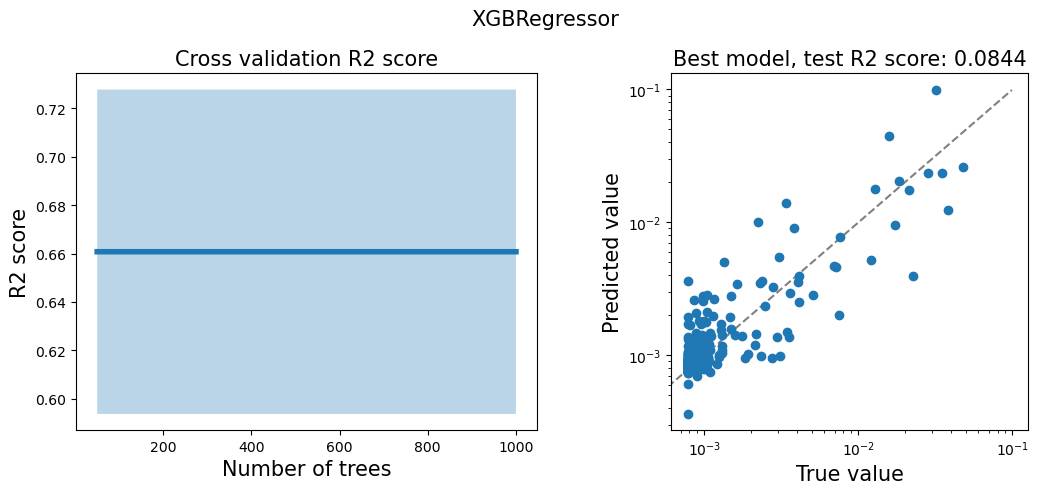

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax[0].plot(n_ests, means, linewidth=4)
ax[0].fill_between(n_ests, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_title("Cross validation R2 score", fontsize=15)
ax[0].set_xlabel("Number of trees", fontsize=15)
ax[0].set_ylabel("R2 score", fontsize=15)
ax[0].tick_params(labelsize=10)

model = model_type(n_estimators=n_ests[means.argmax()])
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax[1].scatter(y_test-minval, y_pred-minval, zorder=10)
ax[1].plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax[1].set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax[1].set_xlabel("True value", fontsize=15)
ax[1].set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax[1].set_ylim(minval, maxval)
ax[1].set_box_aspect(1)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

fig.suptitle(model_type.__name__, fontsize=15)
fig.tight_layout()

## Neural networks

In [62]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader
import torch.utils.data as data_utils
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [63]:
X_train_t, X_train_v, y_train_t, y_train_v = train_test_split(X_train, y_train, test_size=0.2, random_state=17)

X_scaler = StandardScaler().fit(X_train_t)
X_train_t = X_scaler.transform(X_train_t)
X_train_v = X_scaler.transform(X_train_v)

y_scaler = StandardScaler().fit(y_train_t)
y_train_t = y_scaler.transform(y_train_t)
y_train_v = y_scaler.transform(y_train_v)

In [64]:
def train_model(model, X_train, y_train, X_val, y_val, lr=0.001, n_epochs=50, batch_size=32, verbose=False):
    #convert to tensors (for Pytorch)
    X_train_tensor = torch.tensor(X_train).to(device).float()
    y_train_tensor = torch.tensor(y_train).to(device).float()
    X_val_tensor = torch.tensor(X_val).to(device).float()
    y_val_tensor = torch.tensor(y_val).to(device).float()
    
    #intialize neural network
    n_samples, n_features = X_train_tensor.shape
    
    #initialize mse loss function
    criterion = torch.nn.MSELoss(reduction='mean')
    
    #keep track of losses
    train_losses = []
    val_losses = []
    train_r2 = []
    val_r2 = []
    
    #train with SGD
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for e in range(n_epochs):
        
        model.train()
        y_pred = torch.zeros(y_train_tensor.shape).to(device)
        for batch_start in range(0, n_samples, batch_size):
            optimizer.zero_grad()
            X_batch = X_train_tensor[batch_start:batch_start+batch_size]
            y_batch = y_train_tensor[batch_start:batch_start+batch_size]
            y_pred_batch = model(X_batch)
            loss = criterion(y_pred_batch, y_batch)
            loss.backward()
            optimizer.step()
            y_pred[batch_start:batch_start+batch_size] = y_pred_batch
            
        train_losses.append(criterion(y_pred, y_train_tensor).item())
        train_r2.append(r2_score(y_train, y_pred.detach().cpu().numpy()))
        
        #evaluate model:
        model.eval()
        with torch.no_grad():
            y_pred = model(X_val_tensor)
            val_losses.append(criterion(y_pred, y_val_tensor).item())
            val_r2.append(r2_score(y_val, y_pred.detach().cpu().numpy()))
        
        if verbose and e%(n_epochs//5) == 0:
            print(f"[{e}] Train loss: {train_losses[e]:.4f} ({train_r2[e]:.4f}), Val loss: {val_losses[e]:.4f} ({val_r2[e]:.4f})")
    
    return model, np.array(train_losses), np.array(val_losses), np.array(train_r2), np.array(val_r2)

In [65]:
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 50),
    nn.ReLU(),
    nn.Linear(50, 1),
).to(device)

lr = 0.001
n_epochs = 1000

model, train_losses, val_losses, train_r2, val_r2 = train_model(model, X_train_t, y_train_t, X_train_v, y_train_v, lr=lr, n_epochs=n_epochs, verbose=True)

[0] Train loss: 1.1128 (-0.1128), Val loss: 0.7076 (-0.0802)
[200] Train loss: 0.2716 (0.7284), Val loss: 0.2792 (0.5738)
[400] Train loss: 0.2125 (0.7875), Val loss: 0.2507 (0.6173)
[600] Train loss: 0.1881 (0.8119), Val loss: 0.2392 (0.6348)
[800] Train loss: 0.1744 (0.8256), Val loss: 0.2325 (0.6450)


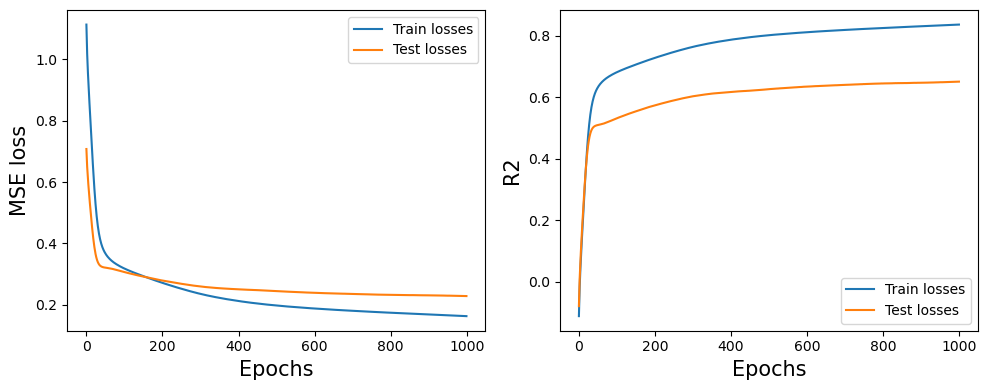

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(train_losses, label="Train losses")
ax[0].plot(val_losses, label="Test losses")

ax[0].set_xlabel('Epochs', fontsize=15)
ax[0].set_ylabel('MSE loss', fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].legend()

ax[1].plot(train_r2, label="Train losses")
ax[1].plot(val_r2, label="Test losses")

ax[1].set_xlabel('Epochs', fontsize=15)
ax[1].set_ylabel('R2', fontsize=15)
ax[1].tick_params(labelsize=10)
ax[1].legend()

fig.tight_layout()
# fig.savefig("nn_losses.png", dpi=150)

## With clustering

In [15]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [53]:
all_data = np.hstack([X, y])
all_data_scalled = StandardScaler().fit_transform(all_data)
all_data_pca = PCA(n_components=2).fit_transform(all_data_scalled)

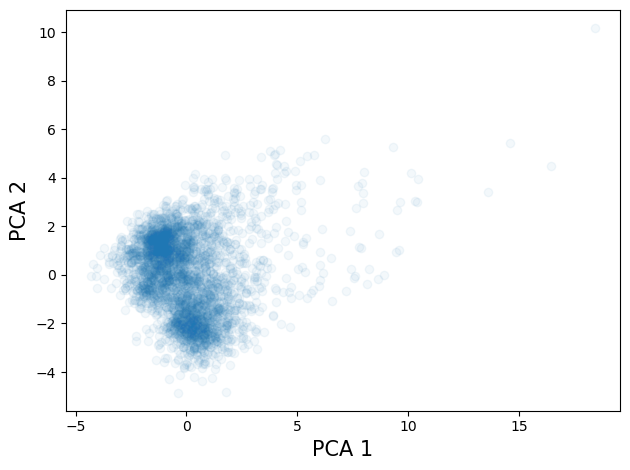

In [54]:
fig, ax = plt.subplots()

ax.scatter(all_data_pca[:,0], all_data_pca[:,1], alpha=0.05)

ax.set_xlabel('PCA 1', fontsize=15)
ax.set_ylabel('PCA 2', fontsize=15)
ax.tick_params(labelsize=10)

fig.tight_layout()

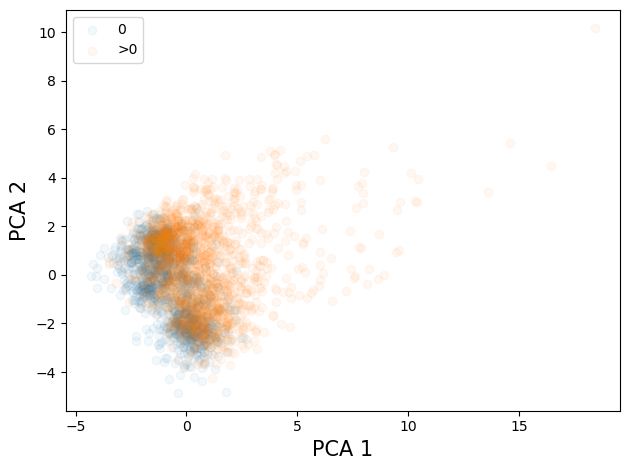

In [55]:
fig, ax = plt.subplots()

mask = y.flatten()==0
ax.scatter(all_data_pca[mask,0], all_data_pca[mask,1], alpha=0.05, label="0")
mask = y.flatten()>0
ax.scatter(all_data_pca[mask,0], all_data_pca[mask,1], alpha=0.05, label=">0")

ax.set_xlabel('PCA 1', fontsize=15)
ax.set_ylabel('PCA 2', fontsize=15)
ax.tick_params(labelsize=10)
ax.legend()

fig.tight_layout()

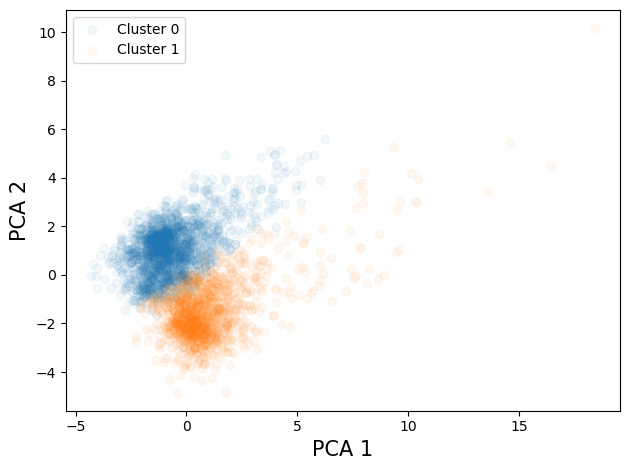

In [58]:
fig, ax = plt.subplots()

km_scaler = StandardScaler()
X_scalled = km_scaler.fit_transform(X)
km = KMeans(n_clusters=2)
clusters = km.fit_predict(X_scalled)

for i in np.unique(clusters):
    mask = clusters==i
    ax.scatter(all_data_pca[mask,0], all_data_pca[mask,1], alpha=0.05, label=f"Cluster {i}")

ax.set_xlabel('PCA 1', fontsize=15)
ax.set_ylabel('PCA 2', fontsize=15)
ax.tick_params(labelsize=10)
ax.legend()

fig.tight_layout()

In [85]:
class ClusterModel():
    def __init__(self, ):
        self.n_clusters = 2
        self.X_scaler = StandardScaler()
        self.y_scaler = StandardScaler()
        self.clustering = KMeans(n_clusters=self.n_clusters)
        self.regression = [Ridge(alpha=255)]*self.n_clusters
        # self.regression = [RandomForestRegressor(n_estimators=100, n_jobs=8)]*self.n_clusters
    
    def fit(self, X, y):
        X_scalled = self.X_scaler.fit_transform(X)
        y_scalled = self.y_scaler.fit_transform(y.reshape(-1,1))
        clusters = self.clustering.fit_predict(X_scalled)
        
        for i in range(self.n_clusters):
            mask = clusters==i
            self.regression[i].fit(X_scalled[mask], y_scalled[mask])
            
    def predict(self, X):
        X_scalled = self.X_scaler.transform(X)
        clusters = self.clustering.predict(X_scalled)
        
        y_pred = np.zeros(len(X))
        for i in range(self.n_clusters):
            mask = clusters==i
            y_pred[mask] = self.regression[i].predict(X_scalled[mask]).flatten()
            
        return self.y_scaler.inverse_transform(y_pred.reshape(-1,1))
    
    def score(self, X, y):
        y_pred = self.predict(X)
        return r2_score(y, y_pred)
    
class ClusterModel():
    def __init__(self, ):
        self.clustering = km
        self.n_clusters = km.n_clusters
        self.X_scaler = km_scaler
        self.regression = [Ridge(alpha=432.87612810830615)]*self.n_clusters
        # self.regression = [RandomForestRegressor(n_estimators=100, n_jobs=8)]*self.n_clusters
    
    def fit(self, X, y):
        X_scalled = self.X_scaler.transform(X)
        clusters = self.clustering.predict(X_scalled)
        
        for i in range(self.n_clusters):
            mask = clusters==i
            self.regression[i].fit(X_scalled[mask], y[mask])
            
    def predict(self, X):
        X_scalled = self.X_scaler.transform(X)
        clusters = self.clustering.predict(X_scalled)
        
        y_pred = np.zeros(len(X))
        for i in range(self.n_clusters):
            mask = clusters==i
            y_pred[mask] = self.regression[i].predict(X_scalled[mask]).flatten()
            
        return y_pred.reshape(-1,1)
    
    def score(self, X, y):
        y_pred = self.predict(X)
        return r2_score(y, y_pred)

In [86]:
scores = []

for _ in range(20):
    model = ClusterModel()
    model.fit(X_train, y_train)
    scores.append(model.score(X_test, y_test))
    
print(res_str(scores))

0.2627 ± 0.0000


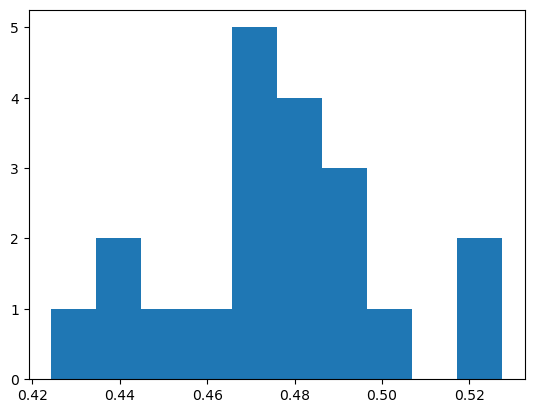

In [81]:
plt.hist(scores)
plt.show()

In [87]:
X_scaler = StandardScaler().fit(X_train)
X_train_2 = X_scaler.transform(X_train)
X_test_2 = X_scaler.transform(X_test)

y_scaler = StandardScaler().fit(y_train)
y_train_2 = y_scaler.transform(y_train)
y_test_2 = y_scaler.transform(y_test)

In [28]:
scores = []

for _ in range(10):
    model = ClusterModel()
    model.fit(X_train_2, y_train)
    scores.append(model.score(X_test_2, y_test))
    
print(res_str(scores))

0.2459 ± 0.0911


In [88]:
scores = []

for _ in range(10):
    model = ClusterModel()
    model.fit(X_train, y_train_2)
    scores.append(model.score(X_test, y_test_2))
    
print(res_str(scores))

0.2627 ± 0.0000


In [ ]:
alphas = np.logspace(1, 4, 100)
scores = []

for alpha in alphas:
    model = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=alpha))])
    scores.append(cross_val_score(model, X_train, y_train, cv=5, n_jobs=5))
    
scores = np.array(scores)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

means = scores.mean(axis=1)
std_err = scores.std(axis=1)/np.sqrt(scores.shape[1])

ax[0].plot(alphas, means, linewidth=4)
ax[0].fill_between(alphas, means-1.96*std_err, means+1.96*std_err, alpha=0.3)

ax[0].set_title("Cross validation R2 score", fontsize=15)
ax[0].set_xlabel("Alpha parameter", fontsize=15)
ax[0].set_ylabel("R2 score", fontsize=15)
ax[0].tick_params(labelsize=10)
ax[0].set_xscale('log')

model = Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=alphas[means.argmax()]))])
model.fit(X_train, y_train.flatten())
y_pred = model.predict(X_test)

minval = np.concatenate([y_test.flatten(), y_pred.flatten()]).min()
maxval = np.concatenate([y_test.flatten(), y_pred.flatten()]).max()
ax[1].scatter(y_test-minval, y_pred-minval, zorder=10)
ax[1].plot([minval, maxval], [minval, maxval], c='grey', linestyle="--")

ax[1].set_title(f"Best model, test R2 score: {model.score(X_test, y_test):.4f}", fontsize=15)
ax[1].set_xlabel("True value", fontsize=15)
ax[1].set_ylabel("Predicted value", fontsize=15)
# ax[1].set_xlim(minval, maxval)
# ax[1].set_ylim(minval, maxval)
ax[1].set_box_aspect(1)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

fig.suptitle("Ridge", fontsize=15)
fig.tight_layout()

## More XGBoost